# What drives a restaurant's rating on Zomato? — Delhi NCR

**Business question.** For a restaurant owner, an investor or Zomato's sales team: which factors — price, cuisine, location, online delivery, table booking — go with a better rating and more visibility?

**Data.** Kaggle *Zomato Restaurant Dataset*: 9,551 restaurants in 15 countries (collection date not stated). The analysis focuses on **Delhi NCR** (New Delhi, Gurgaon, Noida, Faridabad, Ghaziabad): 7,947 restaurants, 83% of the file. Other countries have too few rows and costs are in 12 different currencies.

**Cleaning.** Done in [`clean.py`](clean.py) — see the README for every decision. The key one: a rating of `0` means *not rated* (fewer than 4 votes), not a score of zero.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.width", 120)
BLUE, ORANGE, GREY, INK = "#2a78d6", "#eb6834", "#c4c9d2", "#1f2430"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": "#9aa3b2", "axes.labelcolor": INK, "xtick.color": "#5b6474",
                     "ytick.color": "#5b6474", "axes.titleweight": "bold", "axes.titlesize": 12,
                     "font.size": 10, "axes.grid": True, "grid.color": "#eceef2", "axes.axisbelow": True})

df = pd.read_csv("data/restaurants_clean.csv")
cuisines = pd.read_csv("data/restaurant_cuisines.csv")

ncr = df[df["region"] == "Delhi NCR"].copy()
rated = ncr[ncr["is_rated"]].copy()
print(f"Delhi NCR restaurants: {len(ncr):,}  |  rated: {len(rated):,} ({len(rated)/len(ncr):.0%})")
print(f"Average rating (rated only): {rated['aggregate_rating'].mean():.2f} / 5")
print(f"Average if 'not rated' were wrongly kept as 0: {ncr['aggregate_rating'].fillna(0).mean():.2f} / 5")

Delhi NCR restaurants: 7,947  |  rated: 5,808 (73%)
Average rating (rated only): 3.28 / 5
Average if 'not rated' were wrongly kept as 0: 2.40 / 5


## 1. Price is the factor most linked to the rating

                 restaurants  avg_rating share_4plus  median_votes  median_cost_inr share_not_rated
price_label                                                                                        
1 - Budget              2531        3.18          3%          21.0            300.0             40%
2 - Mid-range           2200        3.25          6%          52.5            600.0             15%
3 - Upscale              783        3.57         23%         168.0           1300.0              4%
4 - Fine dining          294        3.65         24%         148.5           2500.0              4%


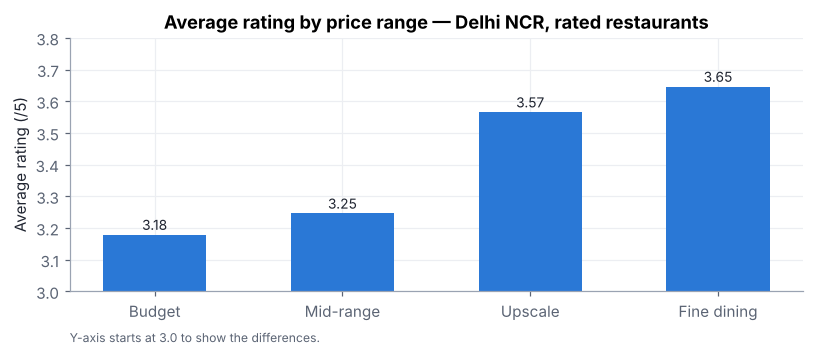

In [2]:
by_price = rated.groupby("price_label").agg(
    restaurants=("restaurant_id", "size"),
    avg_rating=("aggregate_rating", "mean"),
    share_4plus=("aggregate_rating", lambda s: (s >= 4).mean()),
    median_votes=("votes", "median"),
    median_cost_inr=("average_cost_for_two", "median"),
)
by_price["share_not_rated"] = 1 - ncr.groupby("price_label")["is_rated"].mean()
display_table = by_price.copy()
for c in ["share_4plus", "share_not_rated"]:
    display_table[c] = (display_table[c] * 100).round(0).astype(int).astype(str) + "%"
print(display_table.round(2).to_string())

fig, ax = plt.subplots(figsize=(7.5, 3.4))
labels = [l.split(" - ")[1] for l in by_price.index]
bars = ax.bar(labels, by_price["avg_rating"], color=BLUE, width=0.55)
ax.set_ylim(3.0, 3.8); ax.set_ylabel("Average rating (/5)")
ax.set_title("Average rating by price range — Delhi NCR, rated restaurants")
for b, v in zip(bars, by_price["avg_rating"]):
    ax.text(b.get_x() + b.get_width()/2, v + 0.015, f"{v:.2f}", ha="center", color=INK, fontsize=9)
ax.text(0, -0.2, "Y-axis starts at 3.0 to show the differences.", transform=ax.transAxes, fontsize=8, color="#5b6474")
plt.tight_layout(); plt.savefig("charts/01_rating_by_price.png", dpi=150); plt.show()

Fine-dining places score about **0.5 point higher** than budget ones, and almost a quarter of upscale/fine-dining restaurants reach 4+, versus 3% of budget ones.

## 2. For cheap restaurants the real problem is visibility, not the rating
A restaurant needs at least 4 votes to get a rating. Who stays below that threshold?

Share NOT rated, by online delivery: {'no delivery': '36%', 'online delivery': '4%'}


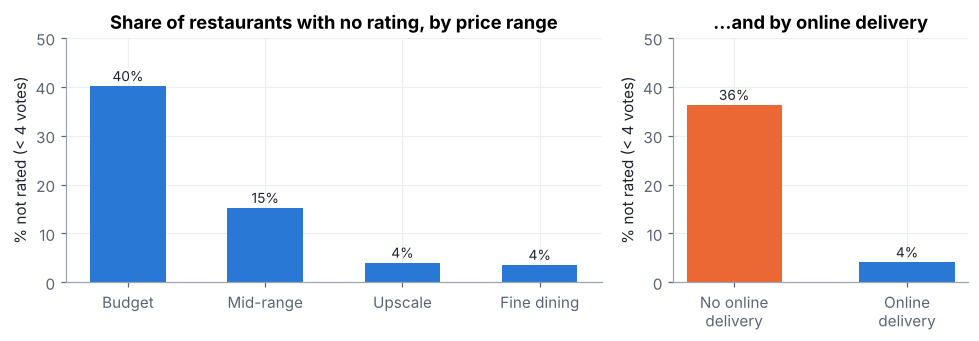

In [3]:
vis = pd.DataFrame({
    "Budget": [1 - ncr.loc[ncr.price_range == 1, "is_rated"].mean()],
    "Mid-range": [1 - ncr.loc[ncr.price_range == 2, "is_rated"].mean()],
    "Upscale": [1 - ncr.loc[ncr.price_range == 3, "is_rated"].mean()],
    "Fine dining": [1 - ncr.loc[ncr.price_range == 4, "is_rated"].mean()],
}).T[0]
deliv = 1 - ncr.groupby("has_online_delivery")["is_rated"].mean()
print("Share NOT rated, by online delivery:", deliv.rename({False: "no delivery", True: "online delivery"}).map("{:.0%}".format).to_dict())

fig, axes = plt.subplots(1, 2, figsize=(9, 3.2), gridspec_kw={"width_ratios": [2, 1.1]})
b = axes[0].bar(vis.index, vis.values * 100, color=BLUE, width=0.55)
axes[0].set_title("Share of restaurants with no rating, by price range")
b2 = axes[1].bar(["No online\ndelivery", "Online\ndelivery"], deliv.values * 100, color=[ORANGE, BLUE], width=0.55)
axes[1].set_title("…and by online delivery")
for ax, bars_, vals in [(axes[0], b, vis.values), (axes[1], b2, deliv.values)]:
    ax.set_ylim(0, 50); ax.set_ylabel("% not rated (< 4 votes)")
    for bb, v in zip(bars_, vals):
        ax.text(bb.get_x() + bb.get_width()/2, v*100 + 1, f"{v:.0%}", ha="center", color=INK, fontsize=9)
plt.tight_layout(); plt.savefig("charts/02_visibility.png", dpi=150); plt.show()

**40% of budget restaurants are invisible** (no rating), versus 4% of upscale ones. Restaurants offering online delivery are almost all rated (4% not rated vs 36% without delivery). Delivery brings orders, orders bring votes: for a small restaurant, being on delivery is first a **visibility lever**. *(Correlation, not proof of cause.)*

## 3. Online delivery: a small effect on the rating, at equal price

In [4]:
pivot = rated.pivot_table(index="price_label", columns="has_online_delivery",
                          values="aggregate_rating", aggfunc="mean").round(2)
pivot.columns = ["No delivery", "Online delivery"]
pivot["Difference"] = (pivot["Online delivery"] - pivot["No delivery"]).round(2)
print(pivot.to_string())

                 No delivery  Online delivery  Difference
price_label                                              
1 - Budget              3.15             3.25        0.10
2 - Mid-range           3.18             3.30        0.12
3 - Upscale             3.57             3.56       -0.01
4 - Fine dining         3.62             3.82        0.20


At equal price, delivery goes with roughly **+0.1 point** for budget and mid-range restaurants, and nothing for upscale ones (fine dining has only 38 restaurants with delivery: too few to conclude).

## 4. A trap: table booking *looks* like it raises the rating

Overall: with booking 3.51 vs without 3.23  ->  +0.28

Within each price range:
has_table_booking  no booking  booking
price_label                           
2 - Mid-range            3.24     3.30
3 - Upscale              3.62     3.54
4 - Fine dining          3.78     3.62

Restaurants per cell:
has_table_booking  no booking  booking
price_label                           
2 - Mid-range            1998      202
3 - Upscale               224      559
4 - Fine dining            54      240


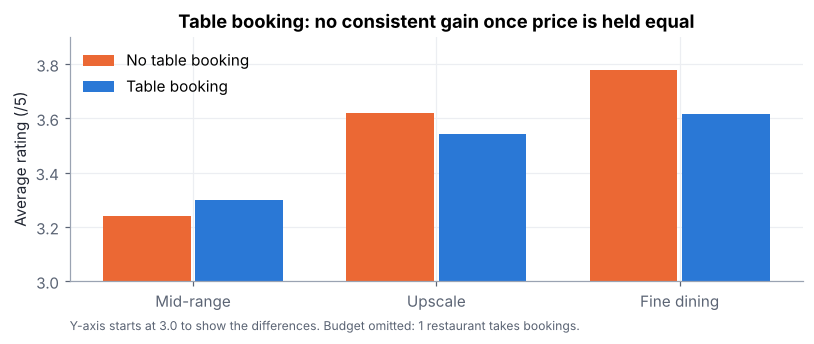

In [5]:
overall = rated.groupby("has_table_booking")["aggregate_rating"].mean()
print(f"Overall: with booking {overall[True]:.2f} vs without {overall[False]:.2f}  ->  +{overall[True]-overall[False]:.2f}")

tb = rated.pivot_table(index="price_label", columns="has_table_booking", values="aggregate_rating", aggfunc="mean")
n_tb = rated.pivot_table(index="price_label", columns="has_table_booking", values="restaurant_id", aggfunc="size")
tb, n_tb = tb.drop(index="1 - Budget"), n_tb.drop(index="1 - Budget")   # only 1 budget restaurant takes bookings
print("\nWithin each price range:"); print(tb.round(2).rename(columns={False: "no booking", True: "booking"}).to_string())
print("\nRestaurants per cell:"); print(n_tb.rename(columns={False: "no booking", True: "booking"}).to_string())

fig, ax = plt.subplots(figsize=(7.5, 3.3))
x = np.arange(len(tb)); w = 0.36
ax.bar(x - w/2 - 0.01, tb[False], w, color=ORANGE, label="No table booking")
ax.bar(x + w/2 + 0.01, tb[True], w, color=BLUE, label="Table booking")
ax.set_xticks(x, [l.split(" - ")[1] for l in tb.index]); ax.set_ylim(3.0, 3.9)
ax.set_ylabel("Average rating (/5)"); ax.legend(frameon=False, loc="upper left")
ax.set_title("Table booking: no consistent gain once price is held equal")
ax.text(0, -0.2, "Y-axis starts at 3.0 to show the differences. Budget omitted: 1 restaurant takes bookings.", transform=ax.transAxes, fontsize=8, color="#5b6474")
plt.tight_layout(); plt.savefig("charts/03_table_booking.png", dpi=150); plt.show()

Overall, restaurants taking bookings score **+0.28**. But they are mostly upscale places. Compared **within the same price range**, the gap is small for mid-range and even **reverses** for upscale and fine dining. The booking option is not what drives the rating — price is (a *confounding variable*).

## 5. Cuisines: which ones beat their price range?
Upscale cuisines naturally score higher, so each restaurant's rating is compared with the average of its own price range (*price-adjusted rating*).

               restaurants  avg_rating  vs_price_avg
cuisine                                             
Asian                  146        3.80          0.30
Mexican                 74        3.70          0.30
Beverages              152        3.45          0.26
Mediterranean           59        3.78          0.26
Desserts               432        3.43          0.22
Cafe                   423        3.50          0.22
Burger                 140        3.45          0.20
European                85        3.79          0.20
Mughlai                732        3.22         -0.09
North Indian          2654        3.22         -0.09
Chinese               1897        3.20         -0.10
Raw Meats               80        3.07         -0.11
Pizza                  229        3.14         -0.16
Finger Food             84        3.41         -0.17


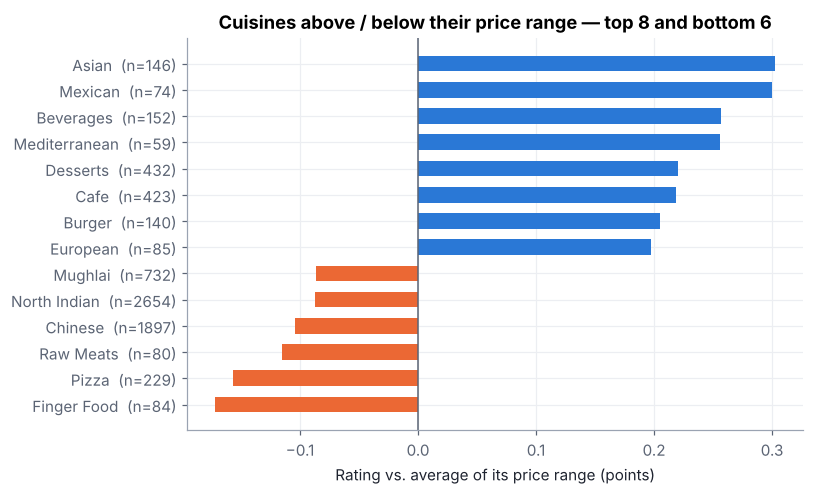

In [6]:
rated["rating_vs_price_avg"] = rated["aggregate_rating"] - rated.groupby("price_range")["aggregate_rating"].transform("mean")
c = cuisines.merge(rated[["restaurant_id", "aggregate_rating", "rating_vs_price_avg"]], on="restaurant_id")
cu = (c.groupby("cuisine").agg(restaurants=("restaurant_id", "size"),
                               avg_rating=("aggregate_rating", "mean"),
                               vs_price_avg=("rating_vs_price_avg", "mean"))
        .query("restaurants >= 40").sort_values("vs_price_avg"))
pick = pd.concat([cu.head(6), cu.tail(8)])
print(pick.round(2).iloc[::-1].to_string())

fig, ax = plt.subplots(figsize=(7.5, 4.6))
colors = [BLUE if v > 0 else ORANGE for v in pick["vs_price_avg"]]
ax.barh([f"{i}  (n={n})" for i, n in zip(pick.index, pick["restaurants"])], pick["vs_price_avg"], color=colors, height=0.6)
ax.axvline(0, color="#5b6474", lw=1)
ax.set_xlabel("Rating vs. average of its price range (points)")
ax.set_title("Cuisines above / below their price range — top 8 and bottom 6")
plt.tight_layout(); plt.savefig("charts/04_cuisines.png", dpi=150); plt.show()

Asian, Mexican and Mediterranean restaurants — and also cafés, desserts and burgers — **outperform their price range**. The most common cuisines (North Indian, Chinese, Mughlai) and pizza **underperform**: a crowded, average-quality market where a good restaurant can stand out.

## 6. Localities

In [7]:
loc = (rated.groupby(["city", "locality"])
       .agg(restaurants=("restaurant_id", "size"), avg_rating=("aggregate_rating", "mean"),
            median_votes=("votes", "median"), share_4plus=("aggregate_rating", lambda s: (s >= 4).mean()))
       .query("restaurants >= 20").sort_values("avg_rating", ascending=False))
loc["share_4plus"] = (loc["share_4plus"] * 100).round(0).astype(int).astype(str) + "%"
print("Best-rated localities (20+ rated restaurants):"); print(loc.head(8).round(2).to_string())
print("\nLowest-rated:"); print(loc.tail(5).round(2).to_string())

Best-rated localities (20+ rated restaurants):
                                                restaurants  avg_rating  median_votes share_4plus
city      locality                                                                               
Gurgaon   Sector 29                                      38        3.89         293.0         42%
          Cyber Hub, DLF Cyber City                      41        3.86         622.0         37%
New Delhi Hauz Khas Village                              24        3.85         823.5         33%
Noida     DLF Mall of India, Sector 18,  Noida           31        3.84         212.0         32%
Gurgaon   DLF Phase 4                                    21        3.80         151.0         33%
New Delhi Khan Market                                    43        3.80         391.0         33%
          Connaught Place                               119        3.78         799.0         27%
          Select Citywalk Mall, Saket                    25        3.76

## Key findings & recommendations

| # | Finding | So what? |
|---|---|---|
| 1 | Rating rises with price: 3.18 (budget) → 3.65 (fine dining). | Compare restaurants **within** a price range, never across. |
| 2 | 40% of budget restaurants have no rating; 36% of those without delivery vs 4% with it. | For small restaurants, **online delivery is first a visibility lever** — a clear pitch for Zomato's sales team. |
| 3 | Delivery ≈ +0.1 point at equal price (budget & mid-range). | Real but modest: delivery won't fix a weak product. |
| 4 | Table booking "+0.28" disappears once price is held equal. | A classic confounder — always control for price before concluding. |
| 5 | Asian, Mexican, Mediterranean, cafés & desserts beat their price range; North Indian, Chinese, pizza lag. | Opportunity: differentiated cuisines, or quality in crowded categories. |
| 6 | Sector 29 & Cyber Hub (Gurgaon), Hauz Khas Village, Khan Market, Connaught Place lead. | Benchmarks for a new opening's target standard. |

**Limits.** One snapshot, collection date unknown; ratings are what Zomato users give, not a quality audit; relationships are correlations, not causes.

**Next steps.** Locality *opportunity index* (high demand, few well-rated restaurants) and a Power BI dashboard built on `restaurants_clean.csv` + `restaurant_cuisines.csv`.